make masks

In fMRI analysis, sometime we need to get the neural signal of a specific region-of-interest (ROI) for further analysis.  
  
This notebook uses getting a DMPFC mask as an example, walking us through **several ways** to get the ROI, which includes:
1. coordinates (based on axis & radius);  
2. meta-analysis from neuralsynth or other similar platform;  
3. parcellation atlas.  

# Setting up

In [73]:
from nilearn import image, plotting
from nilearn.maskers import NiftiSpheresMasker
from nilearn.regions import connected_regions
from nilearn import image
from nilearn.masking import intersect_masks
import nibabel as nib
import os
import numpy as np

In [30]:
# change to your own working directary
base_dir = '/lab/neurodata/hqw/Documents/Projects/IDSI_fMRI/isrsa'

Since we want to generate masks that can be applied to our own data set, we need to figure out our data's format, including the shape, image affine, etc.

In [31]:
# load the image of your own data
img_idsi_raw = image.load_img('/lab/neurodata/hqw/Documents/Projects/IDSI_fMRI/spm12w_scripts/derivatives/spm-preproc-epinorm_mole/sub-idsi001/func/sub-idsi001_task-mole_run-02_space-MNI152_desc-swua_bold.nii.gz')

Check the **shape** and the **image affine**

In [32]:
print(img_idsi_raw.shape)
print(img_idsi_raw.affine)

(53, 65, 53, 509)
[[  -3.    0.    0.   78.]
 [   0.    3.    0. -114.]
 [   0.    0.    3.  -72.]
 [   0.    0.    0.    1.]]


As shown above, our fmri data has 3mm spetial resolution, with this corresonding affine.  
Next, we need to record this shape and affine for resampleing purpose.

In [33]:
img_shape_idsi = img_idsi_raw.shape[0:3]
img_affine_idsi = img_idsi_raw.affine

# Get the ROI based on axis and radius

In the case that we have the ROI's coordinates in the MNI space and have the radius, we can get the ROI via the codes below.  
The key function here is nilearn.maskers.NiftiSpheresMasker: https://nilearn.github.io/dev/modules/generated/nilearn.maskers.NiftiSpheresMasker.html  

Key steps include:  
1. providing a brain template
2. make a binarize brain
3. get the coordinates from the binarize brain  

## Get a brain template

We need a 3D brain to make the template. Therefore, we can use the first TR of img_idsi_raw for it.

In [39]:
img_temp = image.index_img(img_idsi_raw,0)

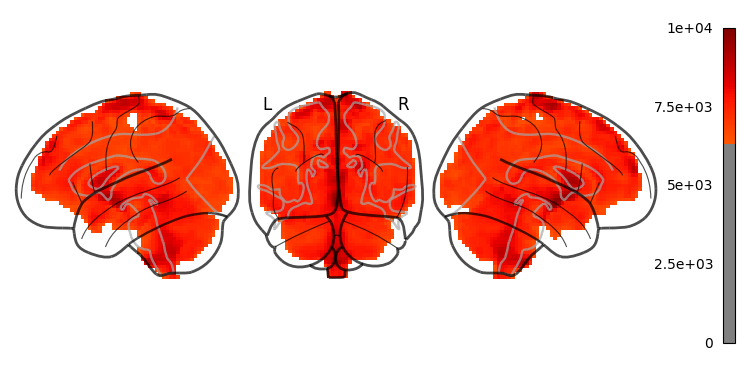

In [40]:
# check the image
plotting.plot_glass_brain(img_temp, display_mode="lyr", colorbar = True, cmap = 'jet')

In [64]:
print(img_temp.shape)
print(img_temp.affine)

(53, 65, 53)
[[  -3.    0.    0.   78.]
 [   0.    3.    0. -114.]
 [   0.    0.    3.  -72.]
 [   0.    0.    0.    1.]]


## Get a binarize brain  
Next, we need to make this image to a binarize image  
Importantly, we need to make sure in the binarize image, the ROI's sphere has values 1 instead of zero.  

In [67]:
img_data = img_temp.get_fdata()
# threshold to leave the 'raw value >= 1000' voxels, basically means the whole brain in a raw data
bi_img_data = img_data >= 1000
bi_img = nib.nifti1.Nifti1Image(bi_img_data,affine=img_temp.affine, header=img_temp.header)

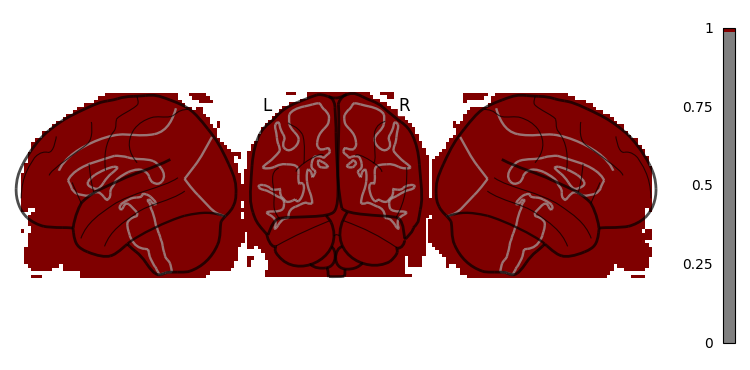

In [68]:
# check the binary brain
plotting.plot_glass_brain(bi_img, display_mode="lyr", colorbar = True, cmap = 'jet')

## Get the ROI based on the coordinates

In [69]:
# coordinate masks - dmpfc Wagner 2016 (2,54,24), radius = 6mm
central_coordinates=[(2,54,24)]
masker_temp = NiftiSpheresMasker(central_coordinates, radius=6, mask_img = bi_img)
masked_data = masker_temp.fit_transform(bi_img)
roi_img = masker_temp.inverse_transform(masked_data)

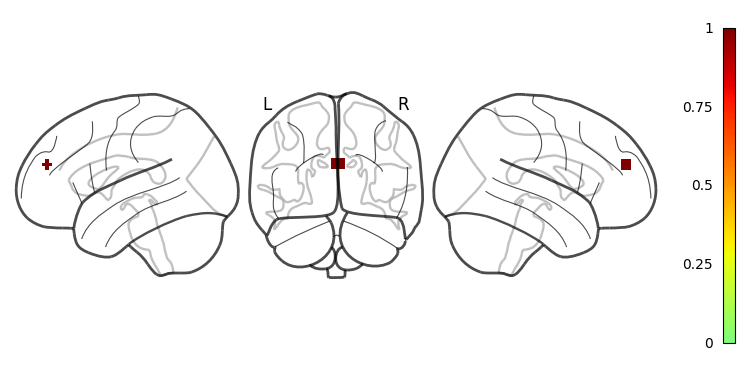

In [70]:
# check to see if it looks normal
plotting.plot_glass_brain(roi_img, display_mode="lyr", colorbar = True, cmap = 'jet')

In [66]:
# check one more time to make sure the mask format match our data
print(roi_img.shape)
print(roi_img.affine)

(53, 65, 53, 1)
[[  -3.    0.    0.   78.]
 [   0.    3.    0. -114.]
 [   0.    0.    3.  -72.]
 [   0.    0.    0.    1.]]


In [90]:
# save the mask for future use
#roi_img.to_filename(os.path.join(base_dir, 'masks','wagner_dmpfc_new_261025.nii'))

# Get the ROI from meta-analysis maps   

Using neurosynth as a mata-analysis example  
  
Information about this example:  
Neurosynth - mentalizing - downloaded in 2/7/2024

Here are the steps: 
1. thresholding(the field usually sets z >=3)  
2. binary convert  
3. resampling  
4. clustering  

First, let's take a look at the raw mask

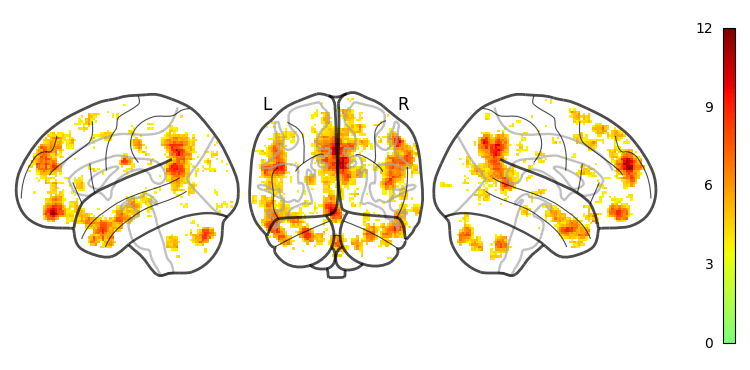

In [15]:
img_temp = image.load_img(os.path.join(base_dir, 'masks','mentalizing_association-test_z_FDR_0.01_240207.nii.gz'))
# check the mask
plotting.plot_glass_brain(img_temp, display_mode="lyr", colorbar = True, cmap = 'jet')

## Convert association mask to binary mask

The association mask we downloaded from neurosynth records z values. But in most of the case we only want to know if that voxel is activated in the specific task. So, here is the code to convert association mask to binary mask. (might include thresholding)

Thresholding & binary converting

In [17]:
img_mask_temp = nib.load(os.path.join(base_dir, 'masks','mentalizing_association-test_z_FDR_0.01_240207.nii.gz'))
img_data = img_mask_temp.get_fdata()
# threshold to leave the z-value >= 3 voxels
new_img_data = img_data >= 3
new_img = nib.nifti1.Nifti1Image(new_img_data,affine=img_mask_temp.affine, header=img_mask_temp.header)

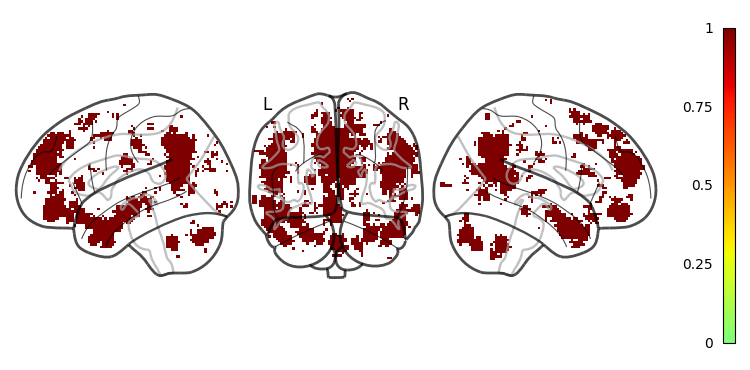

In [18]:
# check the binary brain
plotting.plot_glass_brain(new_img, display_mode="lyr", colorbar = True, cmap = 'jet')

In [19]:
# save the binary mask for future use, please change to your own path before moving forward
#nib.save(new_img, os.path.join(base_dir, 'masks','neurosynth_mental_bi_240207.nii'))

Load the binary mask for clustering

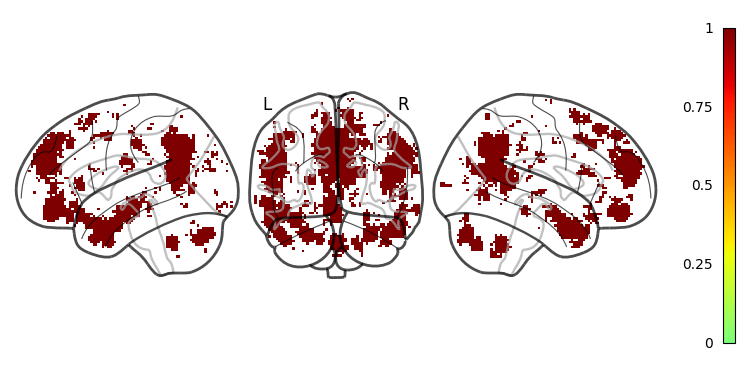

In [20]:
img_temp = image.load_img(os.path.join(base_dir, 'masks','neurosynth_mental_bi_240207.nii'))
# check the mask
plotting.plot_glass_brain(img_temp, display_mode="lyr", colorbar = True, cmap = 'jet')

In [21]:
# check the image shape
img_temp.shape

(91, 109, 91)

In [22]:
img_temp.affine

array([[  -2.,    0.,    0.,   90.],
       [   0.,    2.,    0., -126.],
       [   0.,    0.,    2.,  -72.],
       [   0.,    0.,    0.,    1.]])

## Resample  
As can see above, the mask imported is a 2x2x2 mask. But our data is 3x3x3, so, we need to resample the mask.

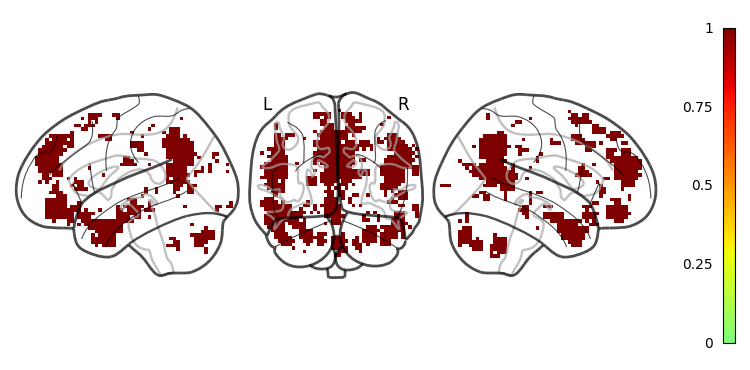

In [23]:
# the package suggests that the binary mask should use nearest interpolation
img_temp_resam = image.resample_img(img_temp, target_affine = img_affine_idsi,target_shape = img_shape_idsi, interpolation='nearest')
plotting.plot_glass_brain(img_temp_resam, display_mode="lyr", colorbar = True, cmap = 'jet')

## Clustering  
Using nilearn.regions -- connected_regions function to calculate connected regions

In [24]:
mask_temp, mask_index = connected_regions(img_temp_resam, min_region_size = 1350)

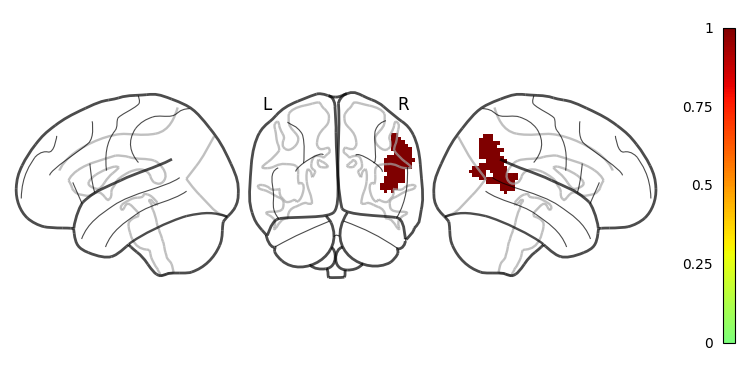

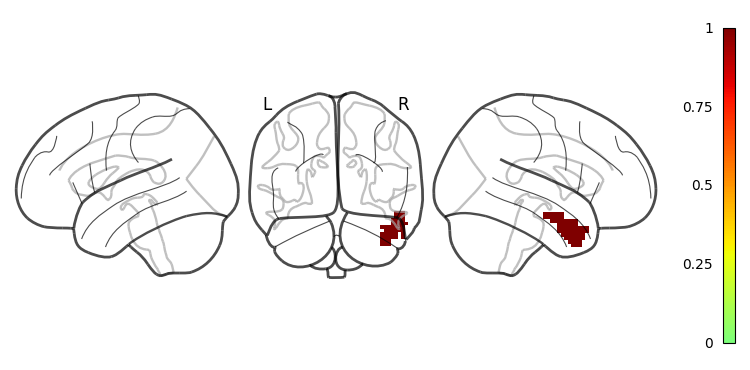

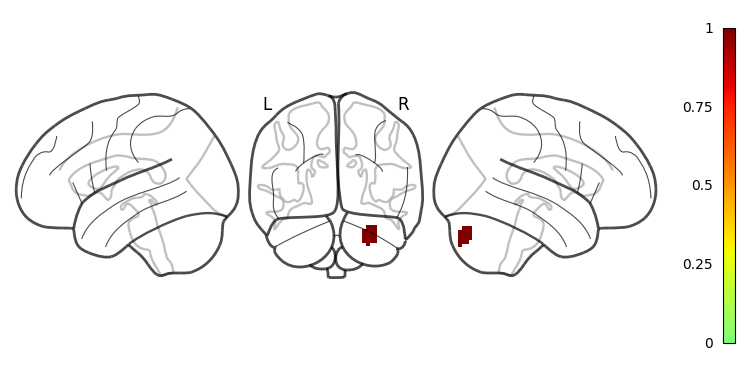

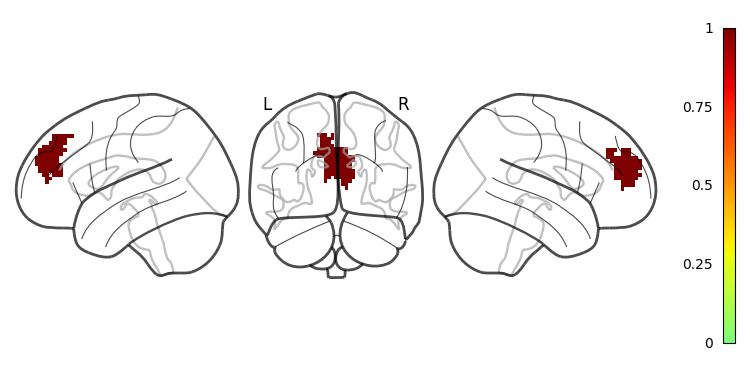

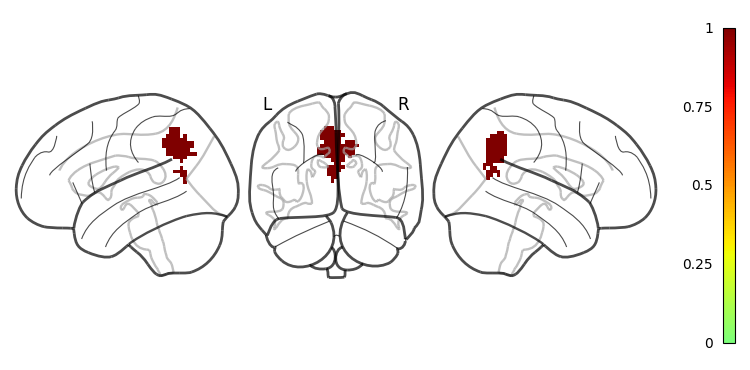

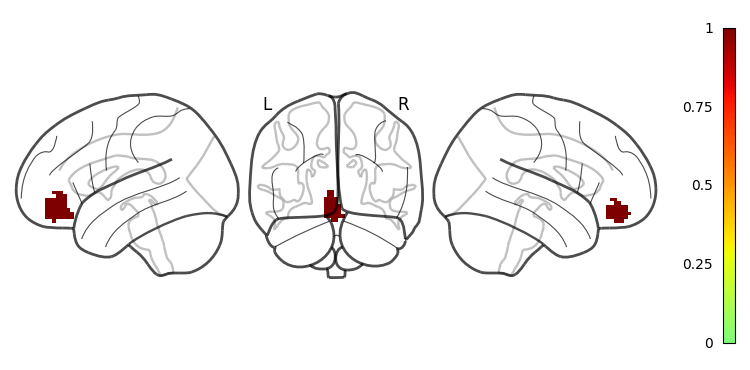

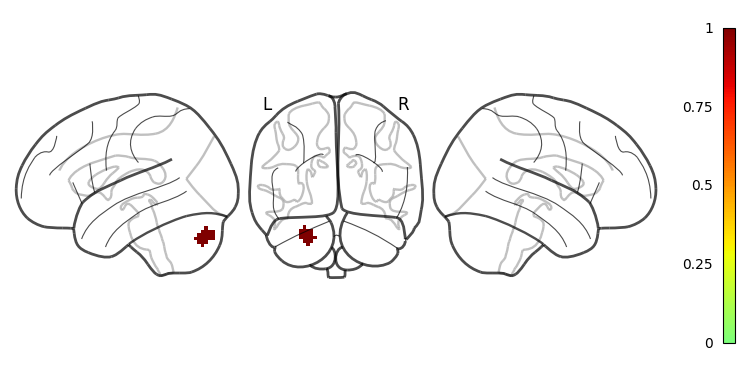

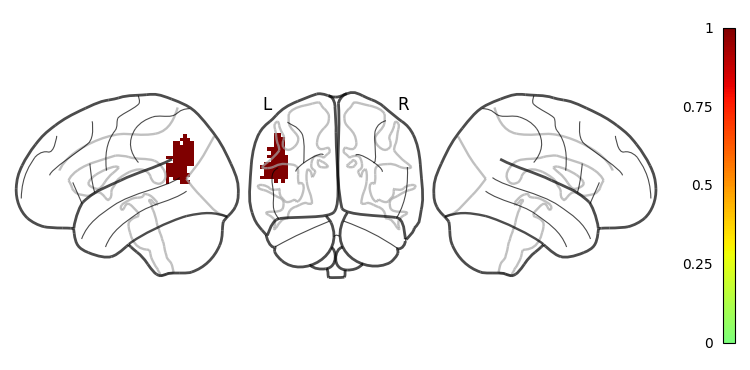

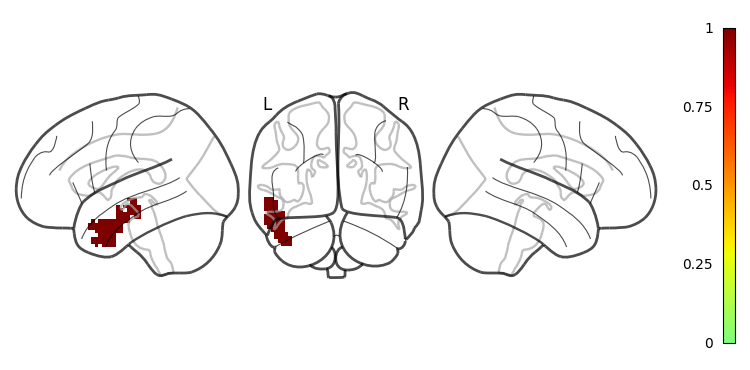

In [25]:
# since the output is a 4D image, we need to convert it to 3D image to visualize
for i in range(len(mask_index)):
    mask_img_temp = image.index_img(mask_temp,i)
    plotting.plot_glass_brain(mask_img_temp, display_mode="lyr", colorbar = True, cmap = 'jet')

After you check the masks' quality, save the results for future use

In [139]:
# for naming the masks easily, I created a name list here based on the clustering results.
mask_name_ls = ['rtpj','rsts','r_cereb','dmpfc','precu','vmpfc','l_cereb','ltpj','lsts']

In [140]:
# to avoid overwrite the results, I commented the code below> 
# Check carefully before uncomment it
#for i in range(len(mask_index)):
#    mask_img_temp = image.index_img(mask_temp,i)
#    f_name = 'nsyn_' + mask_name_ls[i] + '_24-02-07.nii'
#    mask_img_temp.to_filename(os.path.join(base_dir, 'masks',f_name))

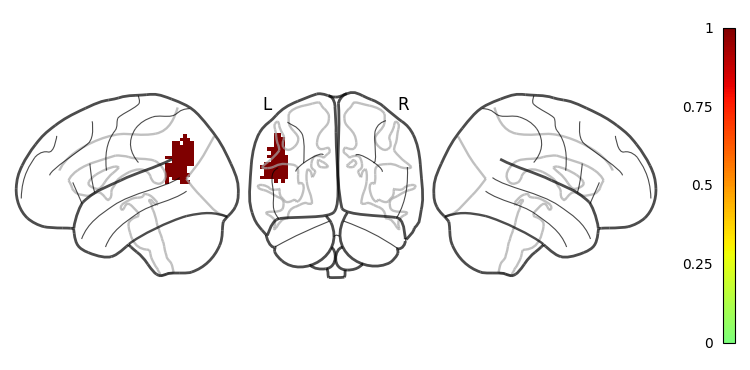

In [138]:
# check if the mask is correct
img_check = image.load_img(os.path.join(base_dir, 'masks','nsyn_ltpj_24-02-07.nii'))
# check the mask
plotting.plot_glass_brain(img_check, display_mode="lyr", colorbar = True, cmap = 'jet')

# Get the ROI from parcellation atlas

Using Schaefer et al., 2018 percellation as an example here  
  
Referenece paper: https://pubmed.ncbi.nlm.nih.gov/28981612/  
Github page: https://github.com/ThomasYeoLab/CBIG/tree/master/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal  
Can also find the label names here: https://github.com/ThomasYeoLab/CBIG/blob/master/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/fsleyes_lut/Schaefer2018_200Parcels_7Networks_order.lut  

Where to download the atlas:  
https://github.com/ThomasYeoLab/CBIG/tree/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI

This atlas provides different combinations of number of networks, number of parcels, and spatial resolutions.  
Here, we will use **200 rois, 17 networks, resolution = 2mm atlas** to get a dmpfc mask.  

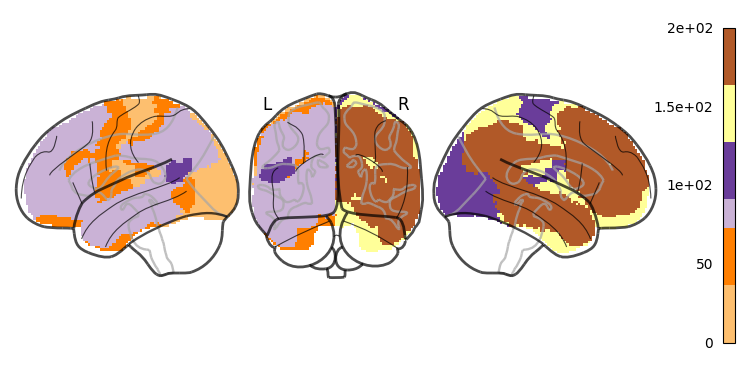

In [92]:
img_temp = image.load_img(os.path.join(base_dir, 'masks','Schaefer2018_200Parcels_17Networks_order_FSLMNI152_2mm.nii.gz'))
# check the mask
plotting.plot_glass_brain(img_temp, display_mode="lyr", colorbar = True, cmap = 'Paired')

Code to visualize a specific parcel (each parcel has its corresponding number, you can find the number and label from the link mentioned above)

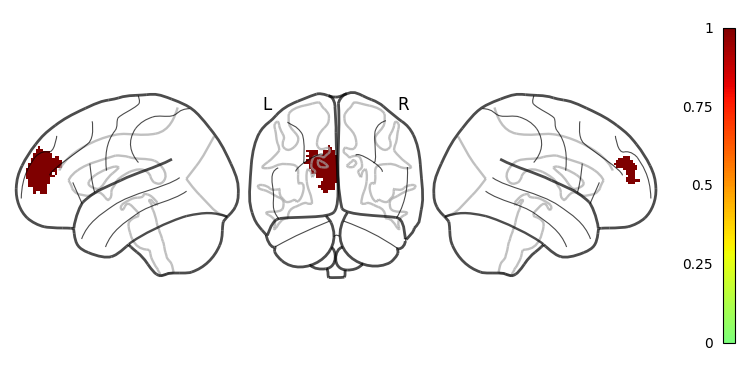

In [93]:
parcel_id = 88
mask_img = image.math_img(f"img == {parcel_id}", img=img_temp)
plotting.plot_glass_brain(mask_img, display_mode="lyr", colorbar = True, cmap = 'jet')

Say that after we explored the parcels and their locations, we decided to get and combine the parcel #88 and the parcel #189 to represent a dmpfc mask.  
Below is the code to do that. But you should be able to use the code to get other parcels that fit your own research.  

The key function to do that is:  
nilear function intersect_masks    
ref: https://nilearn.github.io/dev/modules/generated/nilearn.masking.intersect_masks.html  

## Get the parcels seperately 

In [94]:
# parcel 88
parcel_id = 88
mask_img_dmpfc_temp_1 = image.math_img(f"img == {parcel_id}", img=img_temp)

In [95]:
# parcel 189
parcel_id = 189
mask_img_dmpfc_temp_2 = image.math_img(f"img == {parcel_id}", img=img_temp)

## Combine the parcels

In [96]:
dmpfc_schaefer_200_17 = intersect_masks([mask_img_dmpfc_temp_1, mask_img_dmpfc_temp_2], threshold=0)

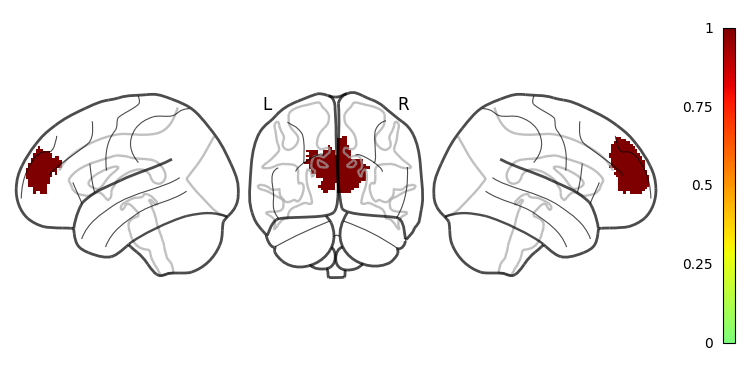

In [97]:
plotting.plot_glass_brain(dmpfc_schaefer_200_17, display_mode="lyr", colorbar = True, cmap = 'jet')

## Resampling

In [98]:
# check the original atlas shape, affine
print(dmpfc_schaefer_200_17.shape)
print(dmpfc_schaefer_200_17.affine)

(91, 109, 91)
[[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]


since our dataset has a different spatial resolution (3mm), we need to resample to atlas to match our data

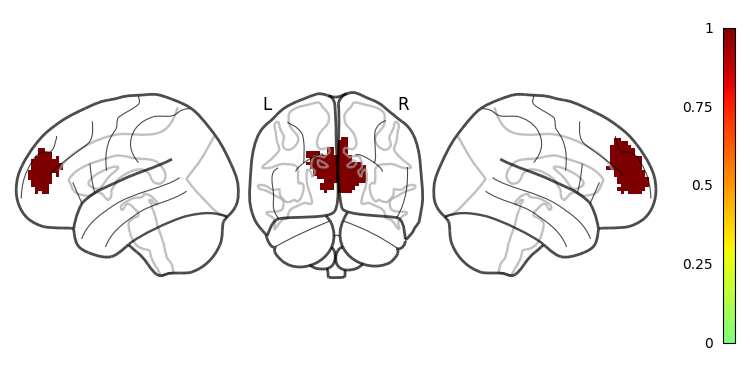

In [99]:
dmpfc_schaefer_200_17_resam = image.resample_img(dmpfc_schaefer_200_17, target_affine = img_affine_idsi,target_shape = img_shape_idsi, interpolation='nearest')
plotting.plot_glass_brain(dmpfc_schaefer_200_17_resam, display_mode="lyr", colorbar = True, cmap = 'jet')

In [ ]:
# save the mask for future use
#dmpfc_schaefer_200_17_resam.to_filename(os.path.join(base_dir, 'masks','schaefer_200_17_dmpfc_260930.nii'))